# Synthetic control with QPB

Classic synthetic control chooses donor weights using only pre-treatment data:
$$\min_{w\geq0,\;\mathbf1^Tw=1}\frac{\|X_{\mathrm{pre}}w-y_{\mathrm{pre}}\|^2}{2T_0}.$$
This is a convex quadratic program. The notebook compares GALAHAD QPB with
SciPy SLSQP and equal donor weights, displays counterfactual paths and weights,
and runs a small zero-effect simulation. The factor-panel DGP is entirely
synthetic, so the untreated path is known for checking recovery.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1008)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from scipy.optimize import minimize
from galahad_econometrics import SyntheticControl

T, T_pre, J = 80, 55, 12
true_weights = np.r_[.2, .3, .5, np.zeros(J-3)]

def simulate(seed, effect=.8):
    random = np.random.default_rng(seed)
    factors = np.cumsum(.15*random.normal(size=(T, 3)), axis=0)
    loadings = random.normal(size=(J, 3))
    common = 2 + .015*np.arange(T)
    donors = common[:, None] + factors @ loadings.T + .2*random.normal(size=(T, J))
    untreated = donors @ true_weights + .04*random.normal(size=T)
    observed = untreated + effect*(np.arange(T) >= T_pre)
    return donors, observed, untreated

donors, observed, untreated = simulate(1008)
X_pre, y_pre = donors[:T_pre], observed[:T_pre]
model = SyntheticControl(X_pre, y_pre)
fit = model.fit()
assert fit.success

reference = minimize(lambda w: .5*np.mean((X_pre @ w-y_pre)**2), np.full(J, 1/J),
                     jac=lambda w: X_pre.T @ (X_pre @ w-y_pre)/T_pre,
                     bounds=[(0, 1)]*J,
                     constraints={"type": "eq", "fun": lambda w: w.sum()-1,
                                  "jac": lambda w: np.ones(J)},
                     method="SLSQP", options={"ftol": 1e-13, "maxiter": 2000})
assert reference.success
assert abs(model.fun(reference.x)-fit.optimization.fun) < 1e-8
assert fit.optimization.feasibility <= 1e-8
assert fit.optimization.optimality <= 1e-8

## Verify constraints before using the forecast

The independent certificate checks nonnegative weights, sum-to-one feasibility,
and the Frank–Wolfe gap. For a feasible vector, the gap bounds objective
suboptimality for this convex problem. Nearly interchangeable donors can produce
coefficient differences much larger than the objective difference. No weights
are clipped or renormalized after optimization.

In [3]:
weights = {"GALAHAD QPB": fit.params, "SciPy SLSQP": reference.x, "Equal weights": np.full(J, 1/J)}
rows = []
for name, w in weights.items():
    counterfactual = donors @ w
    gradient = X_pre.T @ (X_pre @ w-y_pre)/T_pre
    rows.append({"method": name, "pre-period RMSE": np.sqrt(np.mean((counterfactual[:T_pre]-y_pre)**2)),
                 "estimated post effect": np.mean(observed[T_pre:]-counterfactual[T_pre:]),
                 "weight sum": w.sum(), "minimum weight": w.min(),
                 "simplex gap": gradient @ w-gradient.min()})
display(pd.DataFrame(rows).set_index("method"))
print("Known post effect: 0.8; QPB native status:", fit.optimization.status)

,pre-period RMSE,estimated post effect,weight sum,minimum weight,simplex gap
method,,,,,
GALAHAD QPB,0.034889,0.80068,1,3.3883e-08,1.0309e-09
SciPy SLSQP,0.034889,0.80068,1,0,5.1103e-09
Equal weights,0.28613,1.3825,1,0.083333,0.47078


Known post effect: 0.8; QPB native status: 0


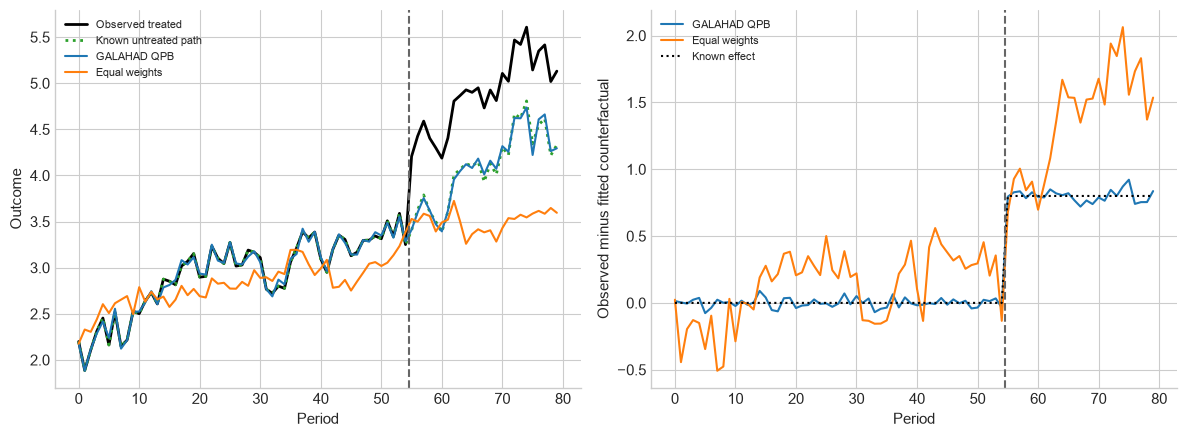

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
periods = np.arange(T)
axes[0].plot(periods, observed, color="black", linewidth=2, label="Observed treated")
axes[0].plot(periods, untreated, color="C2", linestyle=":", linewidth=2, label="Known untreated path")
for name in ["GALAHAD QPB", "Equal weights"]:
    counterfactual = donors @ weights[name]
    axes[0].plot(periods, counterfactual, label=name)
    axes[1].plot(periods, observed-counterfactual, label=name)
axes[1].plot(periods, .8*(periods>=T_pre), color="black", linestyle=":", label="Known effect")
for ax in axes:
    ax.axvline(T_pre-.5, color="0.4", linestyle="--")
    ax.set_xlabel("Period")
axes[0].set_ylabel("Outcome")
axes[1].set_ylabel("Observed minus fitted counterfactual")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

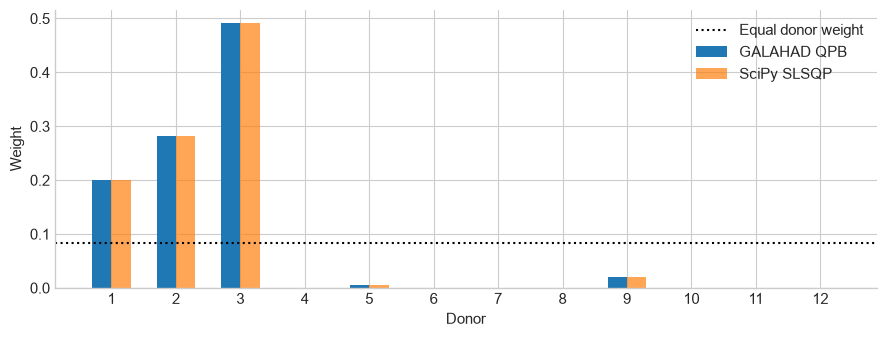

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(J)
ax.bar(x-.15, fit.params, width=.3, label="GALAHAD QPB")
ax.bar(x+.15, reference.x, width=.3, alpha=.7, label="SciPy SLSQP")
ax.axhline(1/J, color="black", linestyle=":", label="Equal donor weight")
ax.set(xticks=x, xticklabels=[str(j+1) for j in x], xlabel="Donor", ylabel="Weight")
ax.legend()
fig.tight_layout()
plt.show()

## A small null-effect simulation

Each of 40 independently seeded panels has zero treatment effect. We estimate
weights from the 55 pre-treatment periods and average the estimated effect over
25 post-treatment periods. Bias is the mean of these 40 run-level effects; RMSE
is the square root of the mean squared run-level effects, including bias.

Every native convergence flag is retained. If a fit fails, it is counted and its
SCM effect is left missing; such failures would make the accepted-fit distribution
an incomplete unconditional comparison. The table reports the number used for
each estimator. The QPB tolerance here is `1e-7`, explicit and smaller than the
statistical variation of this demonstration.

In [6]:
simulation = []
for run in range(40):
    panel, response, counterfactual = simulate(1200+run, effect=0.)
    scm = SyntheticControl(panel[:T_pre], response[:T_pre]).fit(gtol=1e-7, raise_on_failure=False)
    simulation.append({"run": run, "QPB success": bool(scm.success),
                       "native status": scm.optimization.status,
                       "QPB": np.mean(response[T_pre:]-panel[T_pre:] @ scm.params) if scm.success else np.nan,
                       "Equal weights": np.mean(response[T_pre:]-panel[T_pre:].mean(axis=1))})
simulation = pd.DataFrame(simulation)
summary = []
for estimator in ["QPB", "Equal weights"]:
    values = simulation[estimator].dropna().to_numpy()
    summary.append({"estimator": estimator, "runs used": len(values), "runs attempted": 40,
                    "bias": values.mean(), "RMSE": np.sqrt(np.mean(values**2))})
display(pd.DataFrame(summary).set_index("estimator"))
display(simulation.groupby(["QPB success", "native status"]).size().rename("runs").to_frame())

,runs used,runs attempted,bias,RMSE
estimator,,,,
QPB,40,40,0.00095253,0.019662
Equal weights,40,40,0.41922,1.3816


,,runs
QPB success,native status,
True,0,40


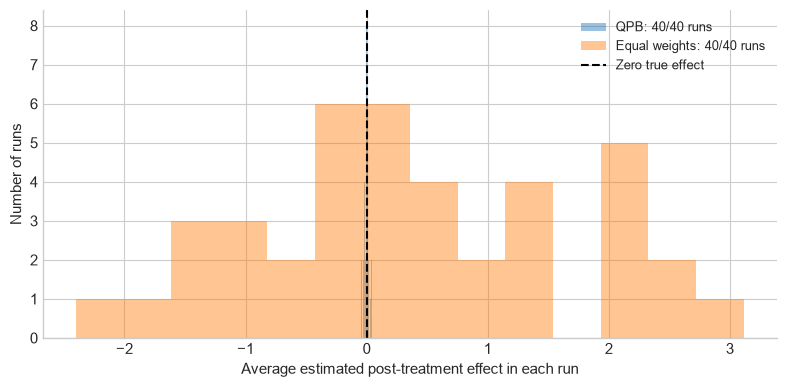

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for estimator in ["QPB", "Equal weights"]:
    values = simulation[estimator].dropna()
    ax.hist(values, bins=14, alpha=.45, label=f"{estimator}: {len(values)}/40 runs")
ax.axvline(0, color="black", linestyle="--", label="Zero true effect")
ax.set(xlabel="Average estimated post-treatment effect in each run", ylabel="Number of runs")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

This DGP intentionally gives the treated unit a well-approximated convex donor
representation. Real applications require substantive identification arguments,
a suitable pre-period and donor pool, and a separate uncertainty design. The
prototype does not supply generic normal standard errors for synthetic control.